Predictions: [1 0 0 1 0 0 0 0 0 1 0 0 1 0 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 0 1 0 0 0 0
 1 1 0 0 0 0 0 1 0 0 1 1 1 1 0 0 1 0 1 0 0 1 0 1 0 0 0 0 1 1 1 0 1 0 0 0 1
 0 0 0 1 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 0 0 1 0 1 0 0 0 0 0 0
 0 0 0 1 1 1 0 1 0 0 1 0 0 0 1 1 1 0 0 1 1 0]
Actual: [np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(1), np.int64(1), np.int64(1), np.int64(0), np.int64(1), np.int64(1), np.in

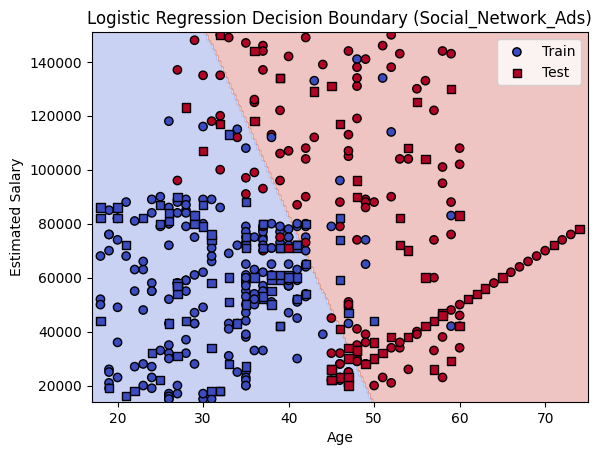

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
df = pd.read_csv("Social_Network_Ads.csv")

# Step 2: Define features and target
X = df[['Age', 'EstimatedSalary']].values
y = df['Purchased'].values

# Step 3: Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Step 4: Train Logistic Regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred = model.predict(X_test)

# Step 6: Evaluate accuracy
print("Predictions:", y_pred)
print("Actual:", list(y_test))
print("Accuracy:", accuracy_score(y_test, y_pred))

# Step 7: Predict for a new employee
new_employee = [[70, 80000]]  # Age=70, Salary=80,000
print("Prediction for new employee:", model.predict(new_employee))

# Step 8: Visualization of decision boundary
# Create mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1000, X[:, 1].max() + 1000
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Predict for each point in grid
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, edgecolors='k', marker='o', cmap=plt.cm.coolwarm, label="Train")
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, edgecolors='k', marker='s', cmap=plt.cm.coolwarm, label="Test")
plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.title("Logistic Regression Decision Boundary (Social_Network_Ads)")
plt.legend()
plt.show()

Logistic Regression Accuracy: 0.8646616541353384
KNN Accuracy: 0.9172932330827067


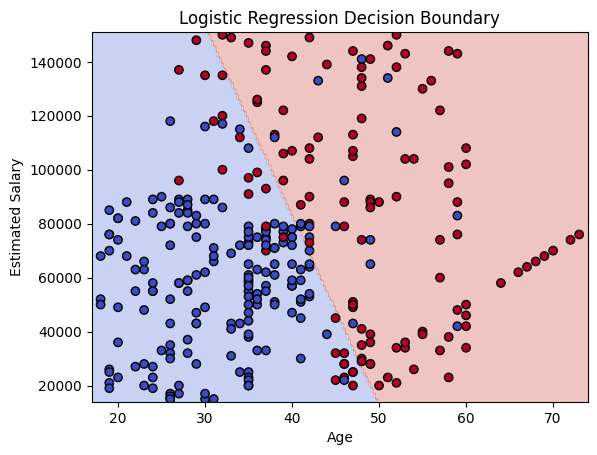

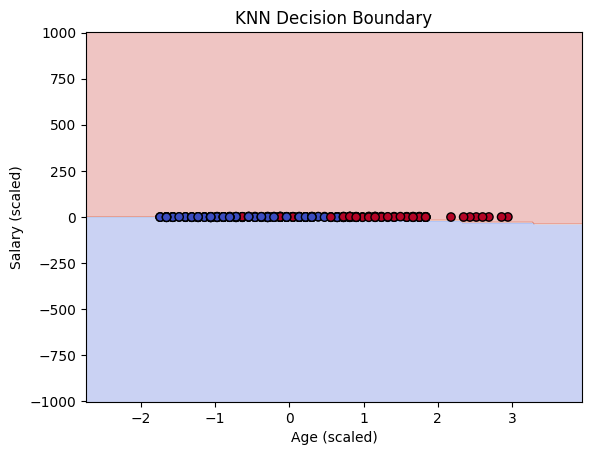

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("Social_Network_Ads.csv")
X = df[['Age', 'EstimatedSalary']].values
y = df['Purchased'].values

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# Scale features (important for KNN, optional for Logistic Regression)
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

# Logistic Regression
log_model = LogisticRegression()
log_model.fit(X_train, y_train)
y_pred_log = log_model.predict(X_test)
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_log))

# KNN
knn_model = KNeighborsClassifier(n_neighbors=3, metric='minkowski', p=2)
knn_model.fit(X_train_scaled, y_train)
y_pred_knn = knn_model.predict(X_test_scaled)
print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))

# Visualization function
def plot_decision_boundary(model, X_train, y_train, title, scaled=False):
    if scaled:
        X_plot = X_train
    else:
        X_plot = X_train

    x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    y_min, y_max = X_plot[:, 1].min() - 1000, X_plot[:, 1].max() + 1000
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))

    if scaled:
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    else:
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    plt.scatter(X_plot[:, 0], X_plot[:, 1], c=y_train, edgecolors='k', cmap=plt.cm.coolwarm)
    plt.xlabel("Age" if not scaled else "Age (scaled)")
    plt.ylabel("Estimated Salary" if not scaled else "Salary (scaled)")
    plt.title(title)
    plt.show()

# Plot Logistic Regression boundary
plot_decision_boundary(log_model, X_train, y_train, "Logistic Regression Decision Boundary")

# Plot KNN boundary (scaled data)
plot_decision_boundary(knn_model, X_train_scaled, y_train, "KNN Decision Boundary", scaled=True)

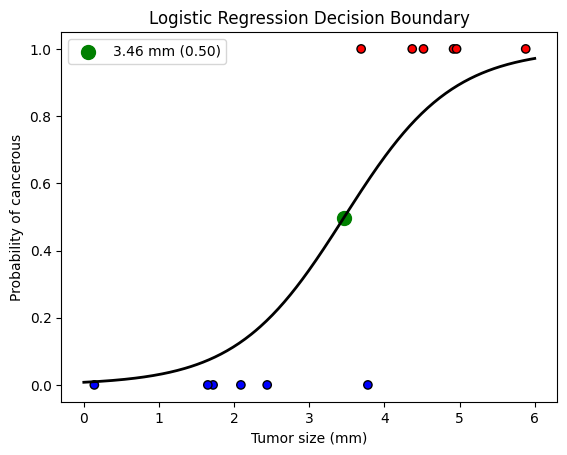

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import linear_model

# Data
X = np.array([3.78, 2.44, 2.09, 0.14, 1.72, 1.65,
              4.92, 4.37, 4.96, 4.52, 3.69, 5.88]).reshape(-1,1)
y = np.array([0, 0, 0, 0, 0, 0,
              1, 1, 1, 1, 1, 1])

# Train logistic regression
logr = linear_model.LogisticRegression()
logr.fit(X, y)

# Range of values for plotting
X_test = np.linspace(0, 6, 300).reshape(-1,1)
y_prob = logr.predict_proba(X_test)[:,1]  # probability of class 1

# Plot
plt.scatter(X, y, c=y, cmap='bwr', edgecolors='k')
plt.plot(X_test, y_prob, color='black', linewidth=2)

# Mark the test point
test_point = 3.46
test_prob = logr.predict_proba(np.array([test_point]).reshape(-1,1))[0,1]
plt.scatter(test_point, test_prob, color='green', s=100, label=f"3.46 mm ({test_prob:.2f})")

plt.xlabel("Tumor size (mm)")
plt.ylabel("Probability of cancerous")
plt.title("Logistic Regression Decision Boundary")
plt.legend()
plt.show()